# Self-RAG Step 5: Iterative Self-Reflection

![Self-RAG Step 5_ Iterative Revision Workflow.png](<attachment:Self-RAG Step 5_ Iterative Revision Workflow.png>)
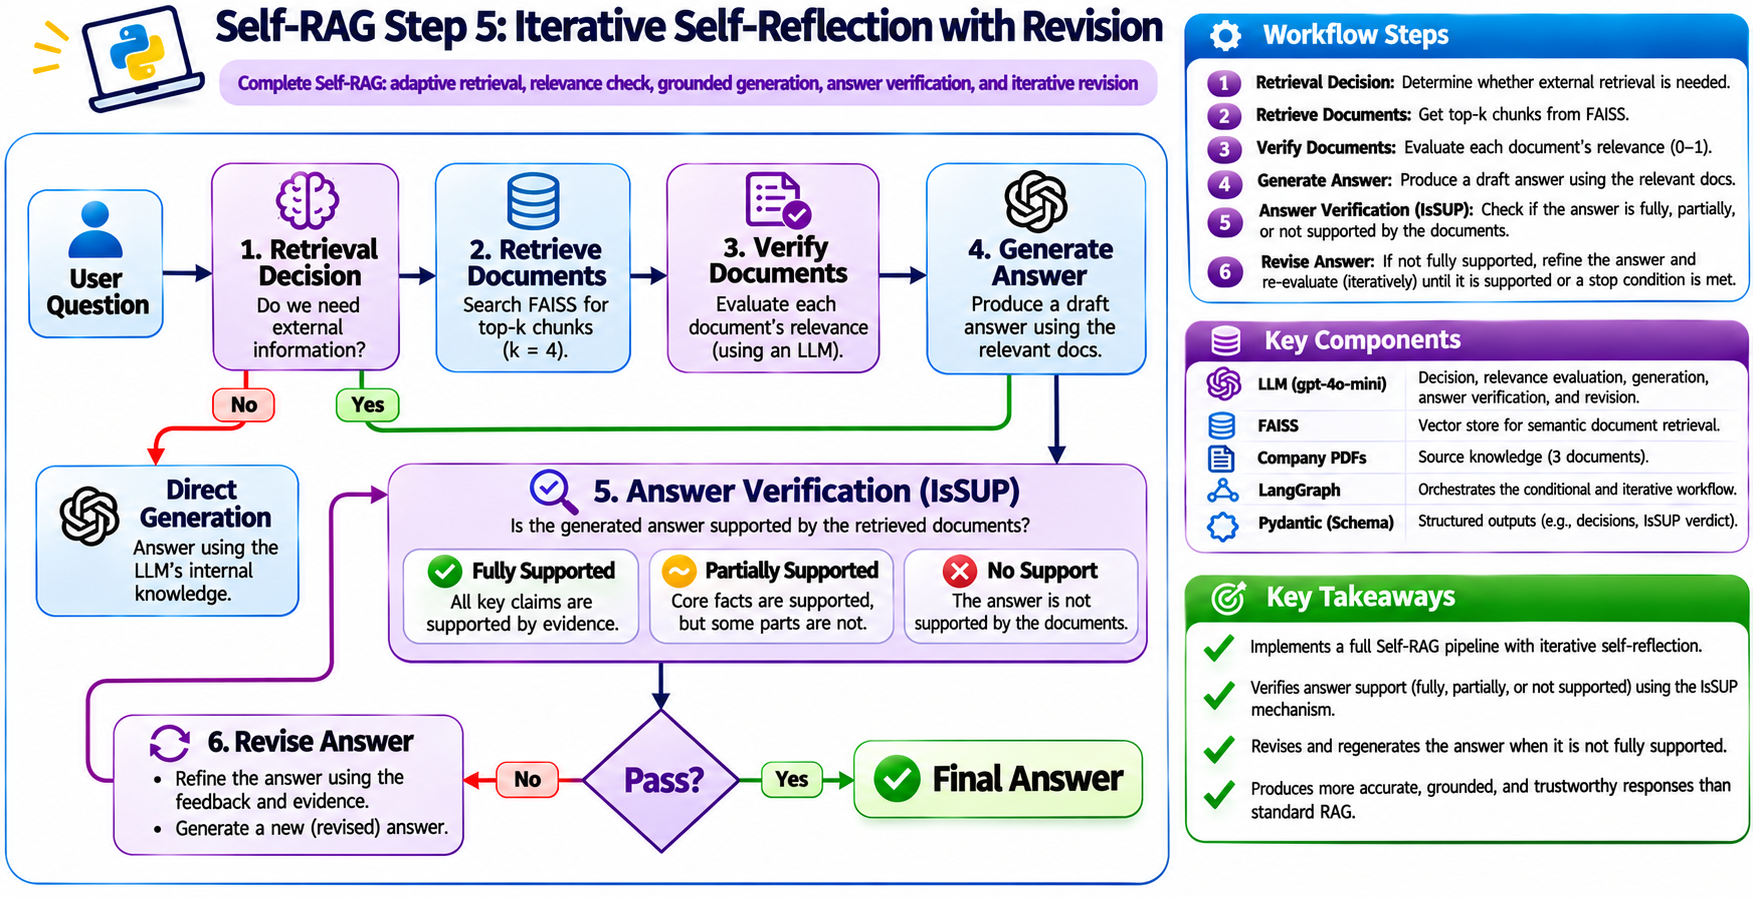


This notebook extends Self-RAG Step 4 by introducing **iterative answer revision** using LangGraph, FAISS, and GPT-4o-mini.

### 1. Main Workflow

```text
User Question → Retrieval Decision
                      |
              ┌───────┴────────┐
              No               Yes
              |                 |
        Direct Answer      FAISS Retrieval
              |                 |
             END          Relevance Check
                                |
                         Relevant Docs?
                          /          \
                         No          Yes
                         |            |
                    No Answer     Generate Answer
                         |            |
                        END          IsSUP
                                      |
                           ┌──────────┴──────────┐
                           |                     |
                    Fully Supported       Not Fully Supported
                           |                     |
                       Accept Answer         Revise Answer
                           |                     |
                          END              Recheck IsSUP
                                               |
                                          Repeat (max 10)
```

### 2. What's New?

The `is_sup()` node evaluates whether the answer is:

- **`fully_supported`**: All meaningful claims are supported.
- **`partially_supported`**: Some statements are unsupported.
- **`no_support`**: Main claims lack supporting evidence.

The `revise_answer()` node rewrites unsupported answers using direct quotations from the retrieved context.

After revision, the answer is evaluated again.

### 3. Revision Control

```python
MAX_RETRIES = 10
```

The `retries` counter prevents an infinite revision loop.

The system stops when the answer is fully supported or the retry limit is reached.

### 4. Key Takeaway

**Step 5 introduces iterative self-correction, allowing the RAG system to evaluate and revise its answers based on retrieved evidence.**

**Important limitation:** When the retry limit is reached, the current code accepts the latest answer even if it remains partially supported or unsupported. A production implementation should return an explicit verification-failure status instead.

In [2]:
import os
from typing import List, TypedDict, Literal
from pydantic import BaseModel, Field

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

# Load API credentials and configuration from the project .env file.
load_dotenv()

api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("BASE_URL")

In [3]:
# Set False to rebuild the FAISS index from the source PDFs; True loads the saved index.
faiss_saved = True

# Build and save the index when no reusable local index is selected.
if faiss_saved==False:
    # Load the company policy, profile, and pricing PDFs as LangChain Documents.
    docs = (
        PyPDFLoader("./documents/DSwithBappy_Company_Policies.pdf").load()
        + PyPDFLoader("./documents/DSwithBappy_Company_Profile.pdf").load()
        + PyPDFLoader("./documents/DSwithBappy_Product_and_Pricing.pdf").load()

    )
    # Split long documents into overlapping passages for retrieval.
    chunks = RecursiveCharacterTextSplitter(
    chunk_size=600, chunk_overlap=150
    ).split_documents(docs)
    # Create the sentence-transformer encoder used for document and query vectors.
    hf_embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')
    # Embed the chunks and build a FAISS similarity-search index.
    vector_store = FAISS.from_documents(chunks, hf_embeddings)
    # Configure retrieval to return the four nearest chunks per query.
    retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})
    
else:
    # Create the sentence-transformer encoder used for document and query vectors.
    hf_embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')
    # Restore the saved FAISS index; only load an index you trust.
    vector_store = FAISS.load_local("faiss_index", hf_embeddings, allow_dangerous_deserialization=True)
    # Configure retrieval to return the four nearest chunks per query.
    retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})


In [4]:
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0, api_key=api_key, base_url=base_url)

In [5]:
# -----------------------------
# Graph State
# -----------------------------
class State(TypedDict):
    question: str
    need_retrieval: bool
    docs: List[Document]
    relevant_docs: List[Document]
    context: str
    answer: str

    # Post-generation verification
    issup: Literal["fully_supported", "partially_supported", "no_support"]
    evidence: List[str]

    # ✅ NEW
    retries: int

In [6]:
# -----------------------------
# 1) Decide retrieval
# -----------------------------
class RetrieveDecision(BaseModel):
    should_retrieve: bool = Field(
        ...,
        description="True if external documents are needed to answer reliably, else False."
    )

decide_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You decide whether retrieval is needed.\n"
            "Return JSON with key: should_retrieve (boolean).\n\n"
            "Guidelines:\n"
            "- should_retrieve=True if answering requires specific facts from company documents.\n"
            "- should_retrieve=False for general explanations/definitions.\n"
            "- If unsure, choose True."
        ),
        ("human", "Question: {question}"),
    ]
)

# Constrain the model response to the retrieval decision schema.
should_retrieve_llm = llm.with_structured_output(RetrieveDecision)

def decide_retrieval(state: State):
    # Decide whether this question needs facts from the local documents.
    decision: RetrieveDecision = should_retrieve_llm.invoke(
        decide_retrieval_prompt.format_messages(question=state["question"])
    )
    # Store the retrieval decision in the graph state for routing.
    return {"need_retrieval": decision.should_retrieve}

# Select direct answering or retrieval based on the decision in state.
def route_after_decide(state: State) -> Literal["generate_direct", "retrieve"]:
    return "retrieve" if state["need_retrieval"] else "generate_direct"


In [7]:
# -----------------------------
# 2) Direct answer (no retrieval)
# -----------------------------
direct_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Answer using only your general knowledge.\n"
            "If it requires specific company info, say:\n"
            "'I don't know based on my general knowledge.'"
        ),
        ("human", "{question}"),
    ]
)

# Answer general questions without consulting the document collection.
def generate_direct(state: State):
    out = llm.invoke(direct_generation_prompt.format_messages(question=state["question"]))
    return {"answer": out.content}


In [8]:
# -----------------------------
# 3) Retrieve
# -----------------------------
def retrieve(state: State):
    # Save retrieved document chunks in graph state.
    return {"docs": retriever.invoke(state["question"])}


In [9]:
# -----------------------------
# 4) Relevance filter 
# -----------------------------
class RelevanceDecision(BaseModel):
    is_relevant: bool = Field(
        ...,
        description="True ONLY if the document contains info that can directly answer the question."
    )

is_relevant_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are judging document relevance at a TOPIC level.\n"
            "Return JSON matching the schema.\n\n"
            "A document is relevant if it discusses the same entity or topic area as the question.\n"
            "It does NOT need to contain the exact answer.\n\n"
            "Examples:\n"
            "- HR policies are relevant to questions about notice period, probation, termination, benefits.\n"
            "- Pricing documents are relevant to questions about refunds, trials, billing terms.\n"
            "- Company profile is relevant to questions about leadership, culture, size, or strategy.\n\n"
            "Do NOT decide whether the document fully answers the question.\n"
            "That will be checked later by IsSUP.\n"
            "When unsure, return is_relevant=true."
        ),
        ("human", "Question:\n{question}\n\nDocument:\n{document}"),
    ]
)


# Return a validated relevance decision instead of free-form text.
relevance_llm = llm.with_structured_output(RelevanceDecision)

def is_relevant(state: State):
    relevant_docs: List[Document] = []
    # Safely evaluate retrieved chunks, including when the state has none.
    for doc in state.get("docs", []):
        decision: RelevanceDecision = relevance_llm.invoke(
            is_relevant_prompt.format_messages(
                question=state["question"],
                document=doc.page_content,
            )
        )
        # Keep only documents the model considers useful evidence.
        if decision.is_relevant:
            relevant_docs.append(doc)
    # Pass the filtered evidence to the next graph node.
    return {"relevant_docs": relevant_docs}

# Continue to grounded generation only when relevant evidence remains.
def route_after_relevance(state: State) -> Literal["generate_from_context", "no_answer_found"]:
    if state.get("relevant_docs") and len(state["relevant_docs"]) > 0:
        return "generate_from_context"
    return "no_answer_found"


In [10]:
# -----------------------------
# 5) Generate from context
# -----------------------------
rag_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a business rag chatbot.\n\n"
            "You will receive a CONTEXT block from internal company documents.\n"
            "Task:\n"
            "Answer the question based on the context"
            "Dont mention that you are getting a context in your answer"
        ),
        ("human", "Question:\n{question}\n\nContext:\n{context}"),
    ]
)

def generate_from_context(state: State):
    # Combine relevant document chunks into the context supplied to the LLM.
    context = "\n\n---\n\n".join([d.page_content for d in state.get("relevant_docs", [])]).strip()
    # Avoid generating a context-based answer when there is no evidence.
    if not context:
        return {"answer": "No answer found.", "context": ""}
    out = llm.invoke(
        rag_generation_prompt.format_messages(question=state["question"], context=context)
    )
    return {"answer": out.content, "context": context}

def no_answer_found(state: State):
    return {"answer": "No answer found.", "context": ""}


In [11]:
# -----------------------------
# 6) IsSUP verify + revise loop
# -----------------------------
class IsSUPDecision(BaseModel):
    issup: Literal["fully_supported", "partially_supported", "no_support"]
    evidence: List[str] = Field(default_factory=list)

issup_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are verifying whether the ANSWER is supported by the CONTEXT.\n"
            "Return JSON with keys: issup, evidence.\n"
            "issup must be one of: fully_supported, partially_supported, no_support.\n\n"
            "How to decide issup:\n"
            "- fully_supported:\n"
            "  Every meaningful claim is explicitly supported by CONTEXT, and the ANSWER does NOT introduce\n"
            "  any qualitative/interpretive words that are not present in CONTEXT.\n"
            "  (Examples of disallowed words unless present in CONTEXT: culture, generous, robust, designed to,\n"
            "  supports professional development, best-in-class, employee-first, etc.)\n\n"
            "- partially_supported:\n"
            "  The core facts are supported, BUT the ANSWER includes ANY abstraction, interpretation, or qualitative\n"
            "  phrasing not explicitly stated in CONTEXT (e.g., calling policies 'culture', saying leave is 'generous',\n"
            "  or inferring outcomes like 'supports professional development').\n\n"
            "- no_support:\n"
            "  The key claims are not supported by CONTEXT.\n\n"
            "Rules:\n"
            "- Be strict: if you see ANY unsupported qualitative/interpretive phrasing, choose partially_supported.\n"
            "- If the answer is mostly unrelated to the question or unsupported, choose no_support.\n"
            "- Evidence: include up to 3 short direct quotes from CONTEXT that support the supported parts.\n"
            "- Do not use outside knowledge."
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Answer:\n{answer}\n\n"
            "Context:\n{context}\n"
        ),
    ]
)



# Require a structured support verdict and evidence quotes.
issup_llm = llm.with_structured_output(IsSUPDecision)

# Verify generated claims against the retrieved context.
def is_sup(state: State):
    decision: IsSUPDecision = issup_llm.invoke(
        issup_prompt.format_messages(
            question=state["question"],
            answer=state.get("answer", ""),
            context=state.get("context", ""),
        )
    )
    return {"issup": decision.issup, "evidence": decision.evidence}


# Bound answer revision attempts to prevent an unending graph loop.
MAX_RETRIES = 3

# Accept supported answers or send unsupported answers for revision.
def route_after_issup(state: State) -> Literal["accept_answer", "revise_answer"]:
    # accept if fully supported
    if state.get("issup") == "fully_supported":
        return "accept_answer"

    # stop if we've already tried enough
    if state.get("retries", 0) >= MAX_RETRIES:
        return "accept_answer"   # or return a "give_up" node if you want

    # otherwise revise again
    return "revise_answer"




In [12]:
def accept_answer(state: State):
    return {}  # keep answer as-is


In [13]:
revise_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a STRICT reviser.\n\n"
            "You must output based on the following format:\n\n"
            "FORMAT (quote-only answer):\n"
            "- <direct quote from the CONTEXT>\n"
            "- <direct quote from the CONTEXT>\n\n"
            "Rules:\n"
            "- Use ONLY the CONTEXT.\n"
            "- Do NOT add any new words besides bullet dashes and the quotes themselves.\n"
            "- Do NOT explain anything.\n"
            "- Do NOT say 'context', 'not mentioned', 'does not mention', 'not provided', etc.\n"
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Current Answer:\n{answer}\n\n"
            "CONTEXT:\n{context}"
        ),
    ]
)



# Rewrite an answer using only direct evidence from the context.
def revise_answer(state: State):
    out = llm.invoke(
        revise_prompt.format_messages(
            question=state["question"],
            answer=state.get("answer", ""),
            context=state.get("context", ""),
        )
    )
    return {
        "answer": out.content,
        # Increment the counter so the support-check loop can terminate.
        "retries": state.get("retries", 0) + 1,  # ✅ increment
    }



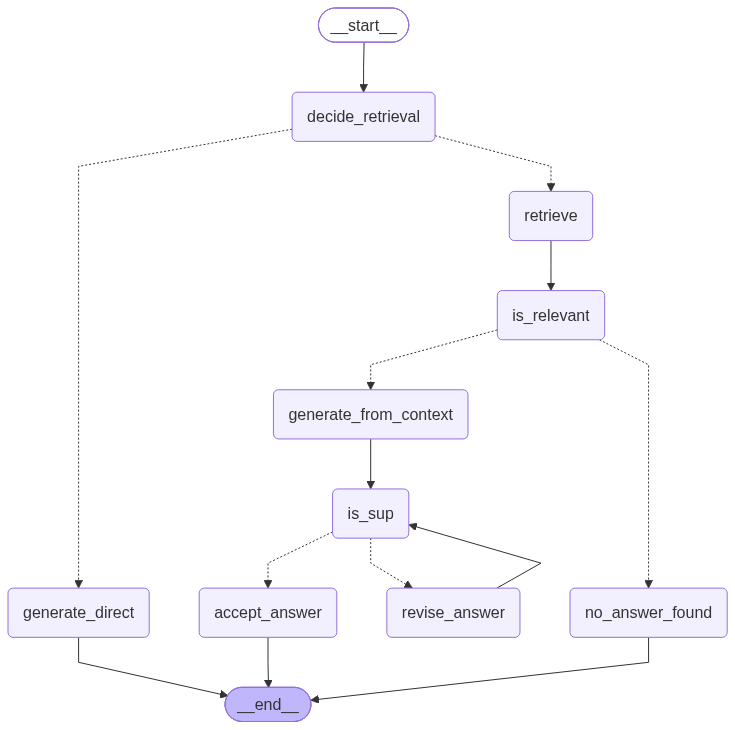

In [14]:
# -----------------------------
# Build graph (REVISED: add accept/revise + loop back to is_sup)
# -----------------------------
g = StateGraph(State)

g.add_node("decide_retrieval", decide_retrieval)
g.add_node("generate_direct", generate_direct)
g.add_node("retrieve", retrieve)

g.add_node("is_relevant", is_relevant)
g.add_node("generate_from_context", generate_from_context)
g.add_node("no_answer_found", no_answer_found)

g.add_node("is_sup", is_sup)

# ✅ NEW nodes
g.add_node("accept_answer", accept_answer)
g.add_node("revise_answer", revise_answer)

# --------------------
# Edges
# --------------------
g.add_edge(START, "decide_retrieval")

# Add a decision-based branch in the workflow.
g.add_conditional_edges(
    "decide_retrieval",
    route_after_decide,
    {"generate_direct": "generate_direct", "retrieve": "retrieve"},
)

g.add_edge("generate_direct", END)

g.add_edge("retrieve", "is_relevant")

# Add a decision-based branch in the workflow.
g.add_conditional_edges(
    "is_relevant",
    route_after_relevance,
    {"generate_from_context": "generate_from_context", "no_answer_found": "no_answer_found"},
)

# If no answer found, end
g.add_edge("no_answer_found", END)

# --------------------
# Verify → (accept | revise) → verify loop
# --------------------
g.add_edge("generate_from_context", "is_sup")

# Add a decision-based branch in the workflow.
g.add_conditional_edges(
    "is_sup",
    route_after_issup,  # fully_supported -> accept_answer else revise_answer
    {"accept_answer": "accept_answer", "revise_answer": "revise_answer"},
)

g.add_edge("revise_answer", "is_sup")  # 🔁 loop back to verify
g.add_edge("accept_answer", END)

# Compile the nodes and edges into an executable graph.
app = g.compile()
app



In [16]:
# Run the complete Self-RAG workflow for the supplied state.
result = app.invoke(
    {
        "question": "Describe DSwithBappy company culture.",
        "docs": [],
        "relevant_docs": [],
        "context": "",
        "answer": "",
        "issup": "",
        "evidence": [],
        "retries": 0,
    },
    config={"recursion_limit": 80},  # ✅ bump limit
)



print("need_retrieval:", result.get("need_retrieval"))
print("#docs:", len(result.get("docs", [])))
print("#relevant_docs:", len(result.get("relevant_docs", [])))
print("issup:", result.get("issup"))
print("evidence:", result.get("evidence"))
print("answer:", result.get("answer"))

need_retrieval: True
#docs: 4
#relevant_docs: 3
issup: fully_supported
evidence: ['DSwithBappy is committed to maintaining a fair, inclusive, collaborative, and performance-driven workplace.', 'All employment and team decisions are made fairly and without discrimination.']
answer: - "DSwithBappy is committed to maintaining a fair, inclusive, collaborative, and performance-driven workplace."
- "All employment and team decisions are made fairly and without discrimination."


In [ ]:
# How many employees does DSwithBappy have?
# Describe DSwithBappy company culture.
# Do DSwithBappy plans include a free trial? If yes, how many days?

In [17]:
print(result.get("retries"))

1


In [ ]:
for doc in result['relevant_docs']:
    print(doc.page_content)